# 3.4 Backtest a 20 días
Una *excepción* ocurre cuando la pérdida real del día supera el VaR estimado con los 500 días anteriores.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import config, utils, plotstyle
plotstyle.apply()
pd.options.display.float_format = "{:.4f}".format
g = pd.read_csv(config.RESULTS_DIR / "var_gan.csv", index_col=0, parse_dates=True)
m = pd.read_csv(config.RESULTS_DIR / "var_montecarlo.csv", index_col=0, parse_dates=True)
bt = pd.read_csv(config.RESULTS_DIR / "backtest_resumen.csv", index_col=0).loc[["GAN propia", "Monte Carlo"]]

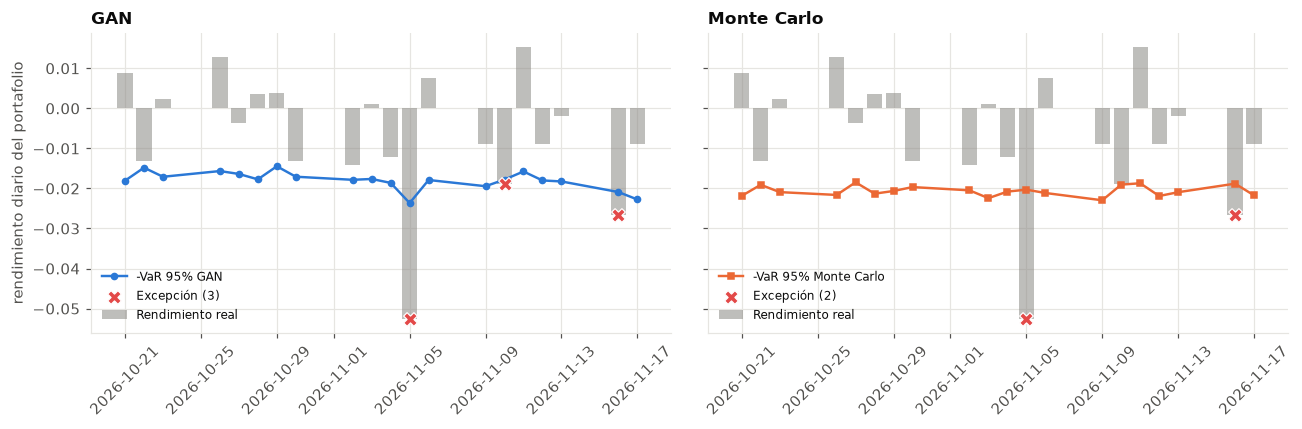

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, df, c, lab, mk in [(axes[0], g, plotstyle.C_GAN, "GAN", "o"), (axes[1], m, plotstyle.C_MC, "Monte Carlo", "s")]:
    ax.bar(df.index, df["realized_return"], color=plotstyle.C_HIST, alpha=0.55, width=0.8, label="Rendimiento real")
    ax.plot(df.index, -df["var_95"], color=c, marker=mk, ms=4, label=f"-VaR 95% {lab}")
    hit = df[df["hit"] == 1]
    ax.scatter(hit.index, hit["realized_return"], marker="X", s=80, color=plotstyle.C_ALERT, zorder=5,
               label=f"Excepción ({len(hit)})", edgecolor="white", linewidth=0.8)
    ax.set_title(lab); ax.legend(loc="lower left", fontsize=8); ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("rendimiento diario del portafolio")
plt.tight_layout(); plotstyle.save(fig, "03_backtest"); plt.show()

## Contrastes de calibración

In [3]:
cols = ["excepciones", "esperadas", "tasa_excepciones", "kupiec_LR", "kupiec_p",
        "exceso_medio_sobre_VaR", "VaR_medio"]
bt[cols].T

,GAN propia,Monte Carlo
excepciones,3.0000,2.0000
esperadas,1.0000,1.0000
tasa_excepciones,0.1500,0.1000
kupiec_LR,2.8100,0.8262
kupiec_p,0.0937,0.3634
exceso_medio_sobre_VaR,0.0119,0.0201
VaR_medio,0.0180,0.0206


**Kupiec (POF)** contrasta que la tasa de excepciones sea 5%.

In [4]:
from scipy.stats import binom
n = config.N_TEST
reject = next(x for x in range(n + 1) if utils.kupiec_pof(np.r_[np.ones(x), np.zeros(n - x)])[1] < 0.05)
print(f"Con {n} días y VaR 95%:")
print(f"  Excepciones esperadas:                       {n * config.ALPHA:.1f}")
print(f"  P(X >= 2) si el modelo es perfecto:          {binom.sf(1, n, config.ALPHA):.1%}")
print(f"  P(X >= 3) si el modelo es perfecto:          {binom.sf(2, n, config.ALPHA):.1%}")
print(f"  Mínimo de excepciones que rechaza a Kupiec:  {reject}  (a nivel 5%)")

Con 20 días y VaR 95%:
  Excepciones esperadas:                       1.0
  P(X >= 2) si el modelo es perfecto:          26.4%
  P(X >= 3) si el modelo es perfecto:          7.5%
  Mínimo de excepciones que rechaza a Kupiec:  4  (a nivel 5%)


In [5]:
ex = pd.concat({"GAN propia": g[g["hit"] == 1], "Monte Carlo": m[m["hit"] == 1]}, names=["modelo", "fecha"])
ex[["var_95", "realized_return"]].rename(columns={"var_95": "VaR", "realized_return": "rendimiento real"})

VaR  rendimiento real
modelo      fecha                              
GAN propia  2026-11-05 0.0236           -0.0527
            2026-11-10 0.0178           -0.0188
            2026-11-16 0.0209           -0.0266
Monte Carlo 2026-11-05 0.0203           -0.0527
            2026-11-16 0.0188           -0.0266

## Observaciones
- **GAN: 3 excepciones (15%); Monte Carlo: 2 (10%)**; con 20 días se espera 1.
- Ambos fallan el **5-nov** (rendimiento real -5.27%) y el **16-nov** (-2.66%). La GAN falla además el 10-nov por un margen mínimo (-1.88% frente a VaR 1.78%).
- **Kupiec no rechaza a ninguno al 5%:** p = 0.094 (GAN) y 0.363 (Monte Carlo). Con 20 días se necesitan **al menos 4 excepciones** para rechazar, y si el modelo fuera perfecto observar 3 o más ocurre con 7.5% de probabilidad. La evidencia es débil: 3 excepciones es una señal de posible subestimación de la GAN, no una prueba.
- El resultado depende mucho de un solo día (-5.27%), que supera al VaR de ambos modelos por un margen amplio.